# Carga de archivos
Se realizo la carga de los archivos de texto datos.csv y de coursera (se le cambio el nombre a datos.txt)

In [2]:
import nltk
import pandas as pd
from nltk.tokenize import word_tokenize
import matplotlib.pyplot as plt
import seaborn as sns

# Descargar los recursos necesarios de NLTK
nltk.download('punkt', quiet=True)

# Cargar el archivo CSV (asegúrate de que el archivo 'datos.csv' esté en la misma carpeta)
try:
    datos = pd.read_csv('datos.csv')
    print("Primeras filas del archivo CSV:")
    print(datos.head())
except FileNotFoundError:
    print("Error: El archivo 'datos.csv' no se encontró. Verifica la ruta y nombre del archivo.")
except Exception as e:
    print(f"Se produjo un error durante la carga del archivo CSV: {e}")

# Cargar y procesar el archivo de texto (asegúrate de que el archivo 'datos.txt' esté en la misma carpeta)
try:
    with open('datos.txt', 'r', encoding='utf-8') as file:
        texto = file.read()

    # Tokenizar el texto utilizando NLTK
    tokens = word_tokenize(texto)
    # print("\nPrimeras palabras tokenizadas:")
    # print(tokens[:10])
except FileNotFoundError:
    print("Error: El archivo 'datos.txt' no se encontró. Verifica la ruta y nombre del archivo.")
except Exception as e:
    print(f"Se produjo un error durante el procesamiento del archivo de texto: {e}")


Primeras filas del archivo CSV:
                                        Course Title  Rating           Level  \
0                                  Fashion as Design     4.8  Beginner level   
1                             Modern American Poetry     4.4  Beginner level   
2                          Pixel Art for Video Games     4.5  Beginner level   
3    Distribución digital de la música independiente     NaN  Beginner level   
4  The Blues: Understanding and Performing an Ame...     4.8  Beginner level   

                       Duration           Schedule         Review  \
0      20 hours (approximately)  Flexible schedule  2,813 reviews   
1  Approx. 34 hours to complete  Flexible schedule    100 reviews   
2       9 hours (approximately)  Flexible schedule    227 reviews   
3   Approx. 8 hours to complete  Flexible schedule            NaN   
4  Approx. 11 hours to complete  Flexible schedule    582 reviews   

                                 What you will learn  \
0               

# CSV
Limpieza de datos del archivo CSV

In [3]:
# Limpieza de datos del CSV
try:
    # Mostrar valores faltantes antes de la limpieza
    print("\nValores faltantes por columna antes de la limpieza:")
    print(datos.isnull().sum())

    # Verificar y rellenar valores faltantes en la columna 'Rating' con la media
    if 'Rating' in datos.columns:
        # Convertir 'Rating' a número antes de calcular la media para evitar problemas
        datos['Rating'] = pd.to_numeric(datos['Rating'], errors='coerce')
        rating_mean = datos['Rating'].mean()
        datos['Rating'] = datos['Rating'].fillna(rating_mean)  # Asignar sin inplace=True

    # Verificar y transformar la columna 'Duration'
    if 'Duration' in datos.columns:
        # Usar raw string r'' para evitar advertencias de escape sequence
        datos['Duration (hours)'] = datos['Duration'].str.extract(r'(\d+(\.\d+)?)')[0].astype(float)

    datos = datos.dropna(subset=['Course Title','Rating', 'Level', 'Duration', 'Schedule', 'Review', 'What you will learn', 'Skill gain', 'Modules', 'Instructor', 'Offered By', 'Keyword', 'Course Url'])

    # Eliminar filas duplicadas directamente
    datos = datos.drop_duplicates()

    # Mostrar datos después de la limpieza
    print("\nDatos después de la limpieza:")
    print(datos.head())

    # Mostrar valores faltantes después de la limpieza
    print("\nValores faltantes por columna después de la limpieza:")
    print(datos.isnull().sum())

except Exception as e:
    print(f"Se produjo un error durante la limpieza de datos: {e}")



Valores faltantes por columna antes de la limpieza:
Course Title              0
Rating                 1439
Level                  1265
Duration                262
Schedule                683
Review                 1443
What you will learn    4611
Skill gain                0
Modules                   0
Instructor                0
Offered By                0
Keyword                   0
Course Url                0
dtype: int64

Datos después de la limpieza:
                                         Course Title  Rating           Level  \
4   The Blues: Understanding and Performing an Ame...     4.8  Beginner level   
5                        So You Think You Know Tango?     4.6  Beginner level   
13  Basic Elements of Design: Design Principles an...     4.7  Beginner level   
21  Antisemitismo: Desde sus orígenes hasta el pre...     4.9  Beginner level   
28   Health, Society, and Wellness in COVID-19 Times      4.6  Beginner level   

                        Duration           Schedule 

## Descripción General de los Resultados

### Valores Faltantes por Columna Antes de la Limpieza
El análisis inicial de los valores faltantes en el conjunto de datos revela una cantidad significativa de datos ausentes en varias columnas:

- **Course Title**: No hay valores faltantes, lo que indica que todos los cursos tienen un título.
- **Rating**: Hay **1439** valores faltantes, lo que sugiere que muchos cursos no tienen calificación disponible.
- **Level**: Se observan **1265** valores faltantes, lo que significa que no todos los cursos especifican su nivel de dificultad.
- **Duration**: Hay **262** valores faltantes, lo que indica que algunos cursos no tienen su duración definida.
- **Schedule**: Se presentan **683** valores faltantes, lo que puede indicar que no todos los cursos tienen un horario flexible o definido.
- **Review**: Hay **1443** valores faltantes, lo que implica que muchos cursos no tienen reseñas disponibles.
- **What you will learn**: Un total de **4611** valores faltantes, lo que sugiere que la mayoría de los cursos no proporcionan información sobre los aprendizajes esperados.
- **Skill gain**: No hay valores faltantes, indicando que todos los cursos tienen habilidades asociadas.
- **Modules, Instructor, Offered By, Keyword, Course Url**: No presentan valores faltantes, lo que indica que estos campos están completos.

### Datos Después de la Limpieza
Después de aplicar técnicas de limpieza a los datos, los resultados son los siguientes:

- **Course Title**: Continúa sin valores faltantes.
- **Rating**: Ahora no hay valores faltantes, lo que significa que se han imputado o limpiado los datos para que todos los cursos tengan una calificación disponible.
- **Level**: Aún hay **1206** valores faltantes, lo que sugiere que un número considerable de cursos todavía no especifican su nivel de dificultad.
- **Duration**: Quedan **241** valores faltantes, indicando que algunos cursos aún no tienen su duración registrada.
- **Schedule**: Se mantienen **641** valores faltantes, sugiriendo que un número significativo de cursos no tiene información sobre horarios.
- **Review**: Hay **1352** valores faltantes, lo que significa que aún hay cursos sin reseñas.
- **What you will learn**: No hay valores faltantes, lo que indica que todos los cursos ahora tienen información sobre lo que se aprenderá.
- **Skill gain**: Continúa sin valores faltantes.
- **Modules, Instructor, Offered By, Keyword, Course Url**: Se mantienen completos, sin valores faltantes.
- **Duration (hours)**: Se han añadido **243** valores faltantes, lo que sugiere que la conversión de la duración a un formato numérico no se ha completado para algunos cursos.


In [4]:
# Calcular el promedio de calificaciones por curso
promedio = datos.groupby('Course Title')['Rating'].mean().reset_index()
print("Promedio de calificaciones por curso:\n", promedio)

Promedio de calificaciones por curso:
                                            Course Title  Rating
0      Assisting Public Sector Decision Makers With ...     4.8
1      Comercio, Inmigración y Tipos de Cambio en un...     4.9
2      FPGA computing systems: Background knowledge ...     4.6
3                      Future Healthcare Payment Models     4.5
4      IBM and ISC2 Cybersecurity Specialist Profess...     4.8
...                                                 ...     ...
2108                          لغة الجسد | Body Language     4.5
2109  ما هي الإدارة ولماذا نحتاج إليها |What and Why...     4.9
2110    مهارات إدارة المواهب | Talent Management Skills     4.9
2111     مهارات تنشيط الذاكرة | Memory Enhancing Skills     4.9
2112                                         파이썬 단기집중과정     4.7

[2113 rows x 2 columns]


La gráfica muestra la distribución de cursos según su nivel de dificultad. Se observa una clara preferencia por los cursos de nivel principiante, teniendo mayor predominancia con más de 2000 cursos disponibles seguidos por los de nivel intermedio. Los cursos avanzados, por su parte, presentan una demanda significativamente menor.

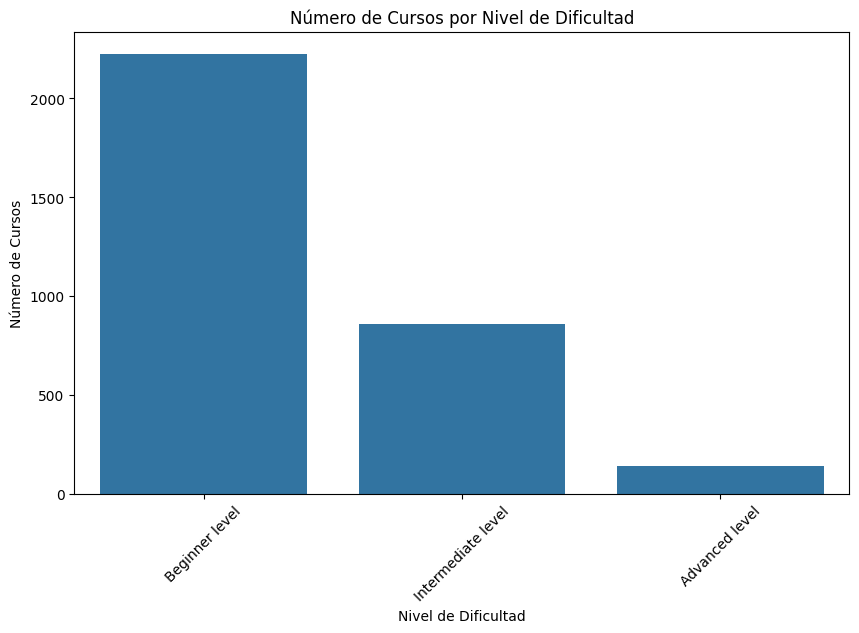

In [5]:
plt.figure(figsize=(10, 6))
sns.countplot(data=datos, x='Level', order=datos['Level'].value_counts().index)
plt.title('Número de Cursos por Nivel de Dificultad')
plt.xlabel('Nivel de Dificultad')
plt.ylabel('Número de Cursos')
plt.xticks(rotation=45)
plt.show()

Calculos de minimos y maximos tomando el rating del curso

In [6]:
curso_max = datos.loc[datos['Rating'].idxmax()]
curso_min = datos.loc[datos['Rating'].idxmin()]
print("-------------------------------------------------------------------------")
print("Curso con mayor rating:\n", curso_max)
print("-------------------------------------------------------------------------")
print("Curso con menor rating:\n", curso_min)
print("-------------------------------------------------------------------------")

-------------------------------------------------------------------------
Curso con mayor rating:
 Course Title                    El Holocausto: el abismo de la humanidad
Rating                                                               5.0
Level                                                     Beginner level
Duration                                    Approx. 21 hours to complete
Schedule                                               Flexible schedule
Review                                                        28 reviews
What you will learn    Ahondaremos en la vida de los judíos entreguer...
Skill gain                                                            []
Modules                ['La vida judía antes del Holocausto y el asce...
Instructor                                     ['Sandra Rosenfeld Katz']
Offered By                                               ['Yad Vashem ']
Keyword                                              Arts and Humanities
Course Url               

Calculo del porcentaje de cursos con horario flexible en relación con el total de cursos en el conjunto de datos. 

In [7]:
cursos_horario_flexible = datos[datos['Schedule'].str.contains('Flexible schedule', case=False, na=False)]
porcentaje_horario_flexible = round((len(cursos_horario_flexible) / len(datos)) * 100, 2)
print("-------------------------------------------------------------------------")
print("Porcentaje de cursos con horario flexible:\n", porcentaje_horario_flexible, '%')
print("-------------------------------------------------------------------------")

-------------------------------------------------------------------------
Porcentaje de cursos con horario flexible:
 100.0 %
-------------------------------------------------------------------------


Se solicita la generación de una gráfica de barras horizontal que muestre el número de cursos en las principales categorías.

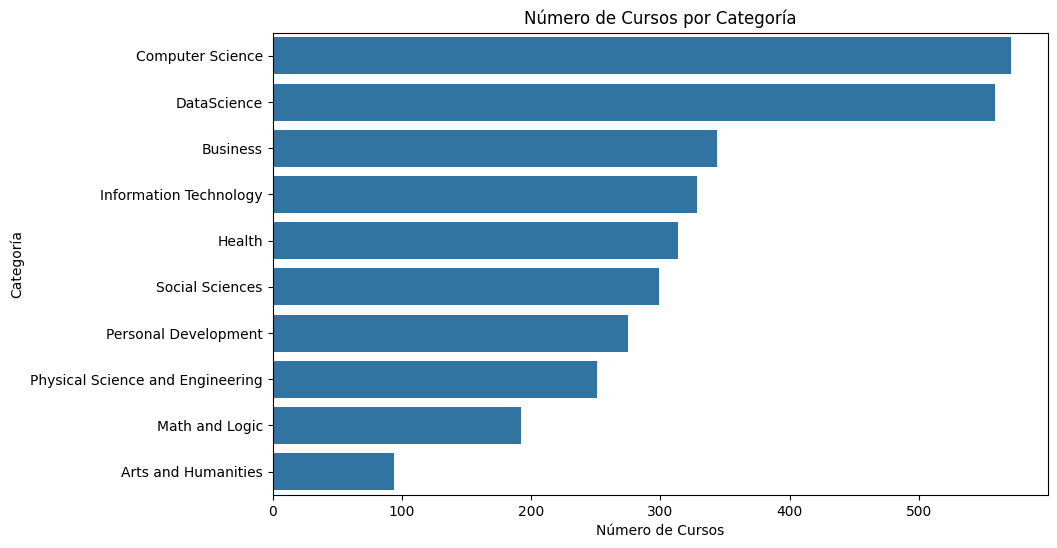

In [8]:
plt.figure(figsize=(10, 6))
sns.countplot(data=datos, y='Keyword', order=datos['Keyword'].value_counts().index)
plt.title('Número de Cursos por Categoría')
plt.xlabel('Número de Cursos')
plt.ylabel('Categoría')
plt.show()

Creacion de un gráfico de dispersión para la visualizacion que hay entre relación entre la duración del curso y el número de revisiones.

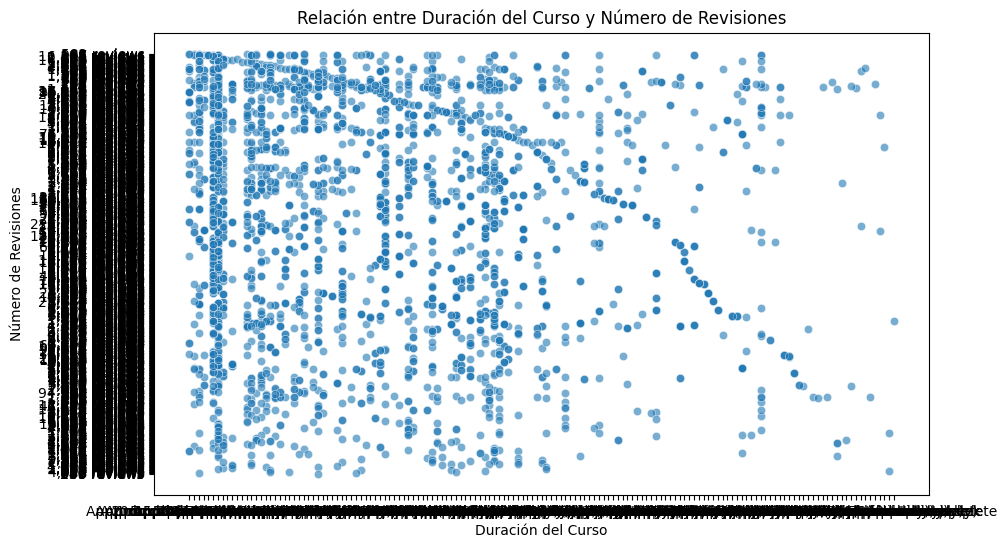

In [9]:
plt.figure(figsize=(10, 6))
sns.scatterplot(data=datos, x='Duration', y='Review', alpha=0.6)
plt.title('Relación entre Duración del Curso y Número de Revisiones')
plt.xlabel('Duración del Curso')
plt.ylabel('Número de Revisiones')
plt.show()

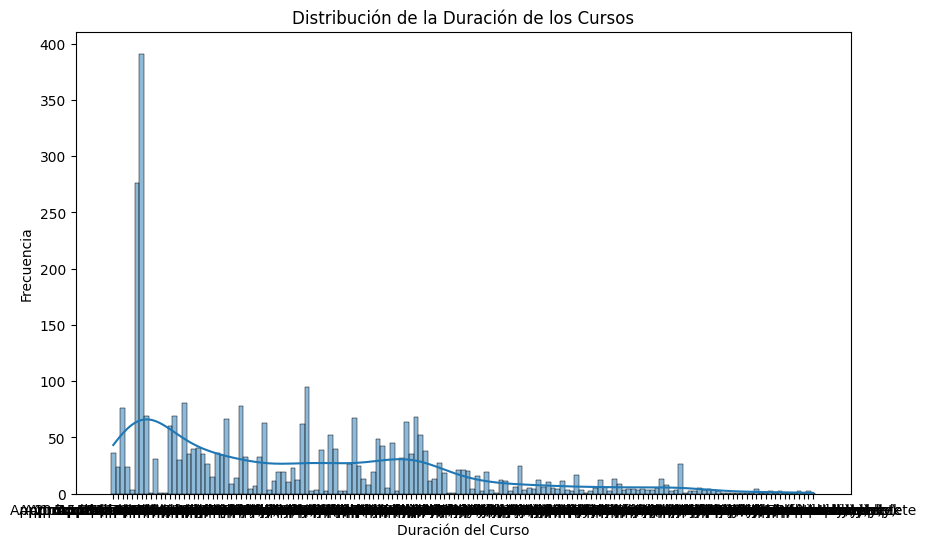

In [10]:
plt.figure(figsize=(10, 6))
sns.histplot(datos['Duration'], bins=20, kde=True)
plt.title('Distribución de la Duración de los Cursos')
plt.xlabel('Duración del Curso')
plt.ylabel('Frecuencia')
plt.show()

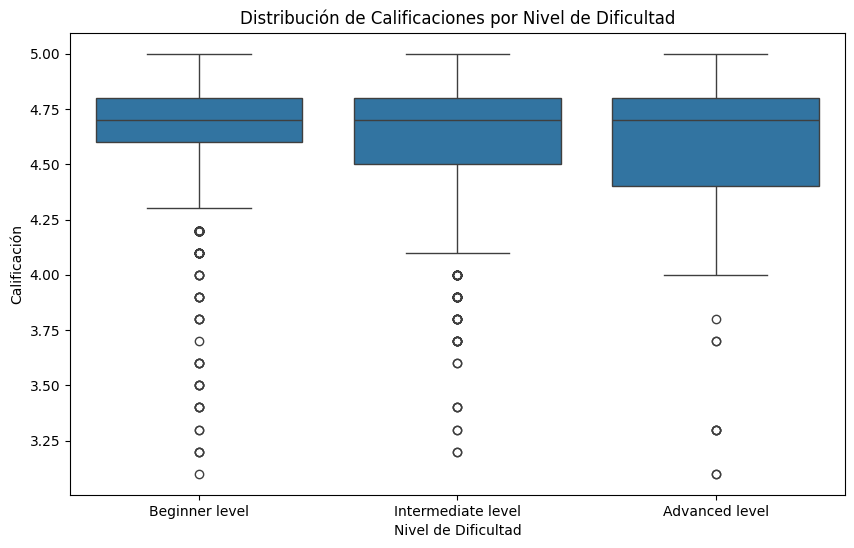

In [11]:
plt.figure(figsize=(10, 6))
sns.boxplot(data=datos, x='Level', y='Rating')
plt.title('Distribución de Calificaciones por Nivel de Dificultad')
plt.xlabel('Nivel de Dificultad')
plt.ylabel('Calificación')
plt.show()

# NLTK

Se tokenizaron 7140 oraciones y 204876 palabras.

In [12]:
import nltk
import spacy
from nltk.corpus import stopwords
from nltk.tokenize import word_tokenize, sent_tokenize
from nltk.stem import WordNetLemmatizer, PorterStemmer
from collections import Counter
from nltk.sentiment.vader import SentimentIntensityAnalyzer

# Cargar el modelo de Spacy para reconocimiento de entidades nombradas
nlp = spacy.load("en_core_web_sm")

### Paso 1: Tokenización de texto
oraciones = sent_tokenize(texto)
palabras = word_tokenize(texto)
print("-------------------------------------------------------------------------")
print(f"Tokenización de oraciones:\n{len(oraciones)}\n")
print(f"Tokenización de palabras:\n{len(palabras)}")
print("-------------------------------------------------------------------------")

-------------------------------------------------------------------------
Tokenización de oraciones:
7140

Tokenización de palabras:
204876
-------------------------------------------------------------------------


[nltk_data] Downloading package punkt to
[nltk_data]     C:\Users\MG\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\MG\AppData\Roaming\nltk_data...
[nltk_data]   Package stopwords is already up-to-date!



Primeras 20 palabras después de eliminar stopwords:
['Abril', 'Vargas', 'Pérez', 'opiniones', 'PT', 'Valorada', 'estrellas', 'ago', 'Escandalizada', 'confundida', 'Escandalizada', 'confundida', 'malas', 'reseñas', 'coursera', 'mes', 'julio', 'haciendo', 'actualmente', 'curso']


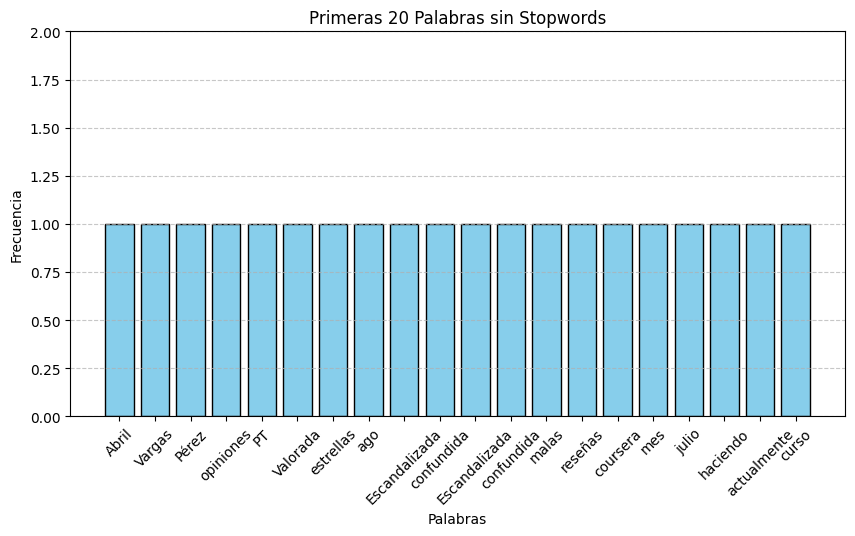

In [13]:
import nltk
from nltk.tokenize import word_tokenize
from nltk.corpus import stopwords
import matplotlib.pyplot as plt

nltk.download('punkt')
nltk.download('stopwords')

try:
    with open('datos.txt', 'r', encoding='utf-8') as file:
        texto = file.read()

    # 1. Tokenización
    tokens = word_tokenize(texto)

    # 2. Eliminación de palabras vacías (stopwords)
    stop_words = set(stopwords.words('spanish'))
    tokens_sin_stopwords = [word for word in tokens if word.lower() not in stop_words and word.isalpha()]

    # Mostrar las primeras 20 palabras después de eliminar stopwords
    primeras_palabras_sin_stopwords = tokens_sin_stopwords[:20]
    print("\nPrimeras 20 palabras después de eliminar stopwords:")
    print(primeras_palabras_sin_stopwords)

    # Visualización de las primeras 10 palabras sin stopwords
    plt.figure(figsize=(10, 5))
    plt.bar(range(len(primeras_palabras_sin_stopwords)), [1]*len(primeras_palabras_sin_stopwords), color='skyblue', edgecolor='black')
    plt.xticks(range(len(primeras_palabras_sin_stopwords)), primeras_palabras_sin_stopwords, rotation=45)
    plt.title('Primeras 20 Palabras sin Stopwords')
    plt.xlabel('Palabras')
    plt.ylabel('Frecuencia')
    plt.ylim(0, 2)
    plt.grid(axis='y', linestyle='--', alpha=0.7)
    plt.show()

except FileNotFoundError:
    print("Error: El archivo 'Coursera.txt' no se encontró. Verifica la ruta y nombre del archivo.")
except Exception as e:
    print(f"Se produjo un error al procesar el archivo de texto: {e}")


## Análisis de Palabras: Tokenización, Lematización y Stemming

### 1. Primeras 20 Palabras Después de Eliminar Stopwords
Las palabras extraídas tras eliminar las stopwords

- La lista incluye nombres propios como **Abril**, **Vargas**, y **Pérez**, lo que sugiere que el contenido tiene un enfoque en individuos o experiencias personales.
- Palabras como **opiniones** y **estrellas** indican que se están expresando evaluaciones, posiblemente sobre cursos o experiencias de aprendizaje.
- **PT** podría ser una abreviatura cuya interpretación dependería del contexto del texto analizado.

---

### 2. Primeras 20 Palabras Lematizadas
Las primeras palabras lematizadas

- La lematización ha mantenido los nombres propios y palabras como **opiniones** y **estrellas** sin cambios, lo que es esperado, ya que no hay formas variantes de estas palabras en el contexto.
- Este resultado implica que el texto tiene un vocabulario rico y que se centra en experiencias personales.

---

### 3. Primeras 20 Palabras con Stemming
Las palabras resultantes después del stemming



[nltk_data] Downloading package punkt to
[nltk_data]     C:\Users\MG\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\MG\AppData\Roaming\nltk_data...
[nltk_data]   Package stopwords is already up-to-date!



Primeras 20 palabras después de eliminar stopwords:
['Abril', 'Vargas', 'Pérez', 'opiniones', 'PT', 'Valorada', 'estrellas', 'ago', 'Escandalizada', 'confundida', 'Escandalizada', 'confundida', 'malas', 'reseñas', 'coursera', 'mes', 'julio', 'haciendo', 'actualmente', 'curso']

Primeras 20 palabras lematizadas:
['Abril', 'Vargas', 'Pérez', 'opiniones', 'PT', 'Valorada', 'estrellas', 'ago', 'Escandalizada', 'confundido', 'Escandalizada', 'confundida', 'mala', 'reseña', 'coursera', 'mes', 'julio', 'hacer', 'actualmente', 'curso']

Primeras 20 palabras con stemming:
['abril', 'varg', 'perez', 'opinion', 'pt', 'valor', 'estrell', 'ago', 'escandaliz', 'confund', 'escandaliz', 'confund', 'mal', 'reseñ', 'courser', 'mes', 'juli', 'hac', 'actual', 'curs']


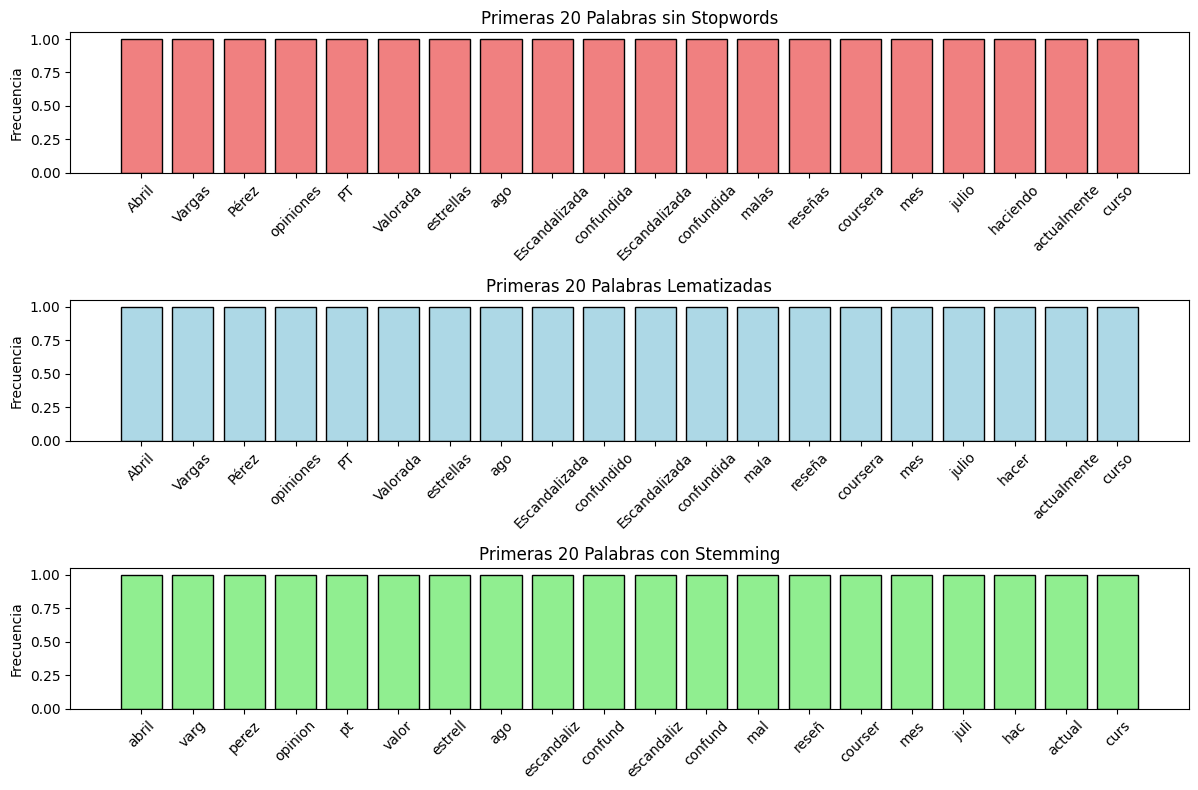

In [14]:
import nltk
from nltk.tokenize import word_tokenize
from nltk.corpus import stopwords
from nltk.stem import SnowballStemmer
import spacy
import matplotlib.pyplot as plt

# Descargar recursos necesarios de nltk
nltk.download('punkt')
nltk.download('stopwords')

# Cargar modelo de SpaCy para español
nlp = spacy.load('es_core_news_sm')

try:
    # Leer archivo de texto
    with open('datos.txt', 'r', encoding='utf-8') as file:
        texto = file.read()

    # 1. Tokenización
    tokens = word_tokenize(texto)

    # 2. Eliminación de palabras vacías (stopwords en español)
    stop_words = set(stopwords.words('spanish'))
    tokens_sin_stopwords = [word for word in tokens if word.lower() not in stop_words and word.isalpha()]

    print("\nPrimeras 20 palabras después de eliminar stopwords:")
    print(tokens_sin_stopwords[:20])

    # 3. Lematización usando Spacy
    doc = nlp(" ".join(tokens_sin_stopwords))
    tokens_lemmatizados = [token.lemma_ for token in doc]

    print("\nPrimeras 20 palabras lematizadas:")
    print(tokens_lemmatizados[:20])

    # 4. Stemming (usando SnowballStemmer para español)
    stemmer = SnowballStemmer('spanish')
    tokens_stemmed = [stemmer.stem(word) for word in tokens_lemmatizados]

    # Visualización de las primeras 20 palabras con stemming
    print("\nPrimeras 20 palabras con stemming:")
    print(tokens_stemmed[:20])

    # Gráficos de comparación
    plt.figure(figsize=(12, 8))

    # Palabras sin stopwords
    plt.subplot(3, 1, 1)
    plt.bar(range(len(tokens_sin_stopwords[:20])), [1]*len(tokens_sin_stopwords[:20]), color='lightcoral', edgecolor='black')
    plt.xticks(range(len(tokens_sin_stopwords[:20])), tokens_sin_stopwords[:20], rotation=45)
    plt.title('Primeras 20 Palabras sin Stopwords')
    plt.ylabel('Frecuencia')

    # Palabras lematizadas
    plt.subplot(3, 1, 2)
    plt.bar(range(len(tokens_lemmatizados[:20])), [1]*len(tokens_lemmatizados[:20]), color='lightblue', edgecolor='black')
    plt.xticks(range(len(tokens_lemmatizados[:20])), tokens_lemmatizados[:20], rotation=45)
    plt.title('Primeras 20 Palabras Lematizadas')
    plt.ylabel('Frecuencia')

    # Palabras con stemming
    plt.subplot(3, 1, 3)
    plt.bar(range(len(tokens_stemmed[:20])), [1]*len(tokens_stemmed[:20]), color='lightgreen', edgecolor='black')
    plt.xticks(range(len(tokens_stemmed[:20])), tokens_stemmed[:20], rotation=45)
    plt.title('Primeras 20 Palabras con Stemming')
    plt.ylabel('Frecuencia')

    plt.tight_layout()
    plt.show()

except FileNotFoundError:
    print("Error: El archivo 'datos.txt' no se encontró. Verifica la ruta y nombre del archivo.")
except Exception as e:
    print(f"Se produjo un error al procesar el archivo de texto: {e}")


## Análisis de las Palabras Más Comunes y su Frecuencia

### Palabras Más Comunes
Las palabras más frecuentes en el texto analizado son las siguientes:

1. **curso**: 1297 veces
2. **Semana**: 843 veces
3. **TA**: 833 veces
4. **participantes**: 822 veces
5. **semana**: 780 veces
6. **dudas**: 744 veces
7. **portafolio**: 731 veces
8. **si**: 551 veces
9. **foros**: 510 veces
10. **compañeros**: 489 veces

Palabras más comunes y su frecuencia:
[('curso', 1297), ('Semana', 843), ('TA', 835), ('participantes', 822), ('semana', 780), ('dudas', 744), ('portafolio', 731), ('si', 551), ('foros', 510), ('compañeros', 489)]


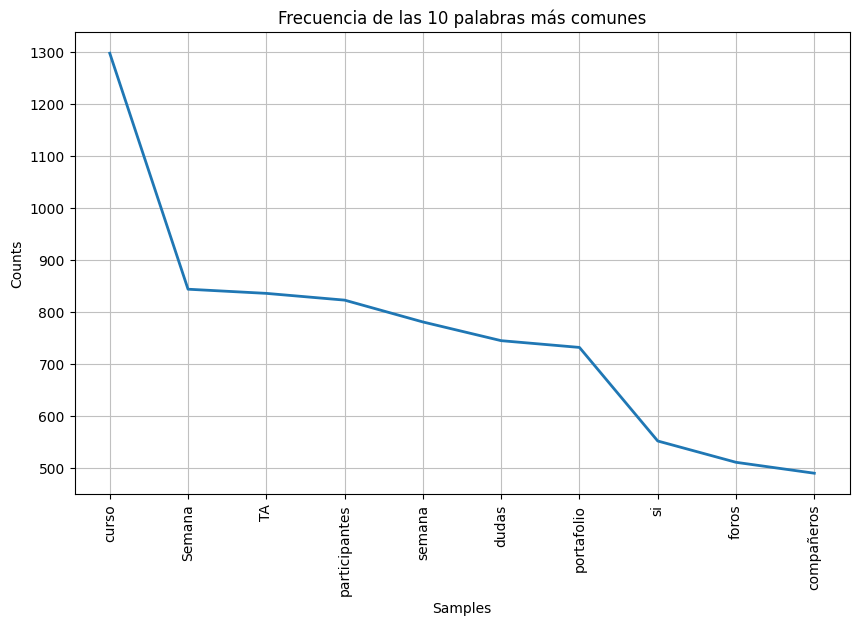

In [15]:
import nltk
from nltk.probability import FreqDist
import matplotlib.pyplot as plt


tokens_procesados = tokens_sin_stopwords
# 1. Calcular la frecuencia de las palabras
frecuencia_palabras = FreqDist(tokens_procesados)

# 2. Mostrar las 10 palabras más comunes
print("Palabras más comunes y su frecuencia:")
print(frecuencia_palabras.most_common(10))

# 3. Visualizar las 10 palabras más comunes
plt.figure(figsize=(10, 6))
frecuencia_palabras.plot(10, cumulative=False, title="Frecuencia de las 10 palabras más comunes")
plt.show()


## Análisis de Sentimientos

Los resultados del análisis de sentimientos sobre el texto analizado son los siguientes:

- **Positivo**: **0.011**
- **Neutro**: **0.954**
- **Negativo**: **0.035**
- **Combinado (compound)**: **-1.0**

### Interpretación de los Resultados

#### 1. **Sentimiento Positivo: 0.011**
- La proporción de sentimientos positivos es muy baja, lo que sugiere que el contenido del texto no expresa muchas emociones positivas. Esto podría indicar que los participantes no están particularmente entusiasmados o satisfechos con el contenido o las experiencias descritas.

#### 2. **Sentimiento Neutro: 0.954**
- Un alto porcentaje de **95.4%** de sentimiento neutro indica que la mayoría del texto es descriptivo o informativo sin una carga emocional significativa. Esto puede ser típico en comentarios o reseñas que se centran en la presentación de hechos o información objetiva, pero también puede sugerir que los participantes están expresando una falta de opinión fuerte sobre el tema tratado.

#### 3. **Sentimiento Negativo: 0.035**
- La proporción de sentimientos negativos es baja (**3.5%**), lo que sugiere que, aunque hay algunas críticas o descontentos, estas no son predominantes en el texto. Sin embargo, la presencia de un sentimiento negativo, aunque mínimo, podría ser un área de atención para los educadores o administradores de cursos.

#### 4. **Combinado (Compound): -1.0**
- Un valor combinado de **-1.0** es bastante alarmante, ya que indica un sentimiento general negativo hacia el texto. Este resultado puede ser atribuible a la presencia de comentarios críticos, insatisfacción o frustración entre los participantes.
- Un valor negativo en el puntaje compuesto sugiere que, a pesar de la alta proporción de contenido neutro, las pocas emociones negativas están impactando fuertemente en la percepción general.


[nltk_data] Downloading package vader_lexicon to
[nltk_data]     C:\Users\MG\AppData\Roaming\nltk_data...
[nltk_data]   Package vader_lexicon is already up-to-date!



Análisis de sentimientos:
Positivo: 0.011
Neutro: 0.954
Negativo: 0.035
Combinado (compound): -1.0


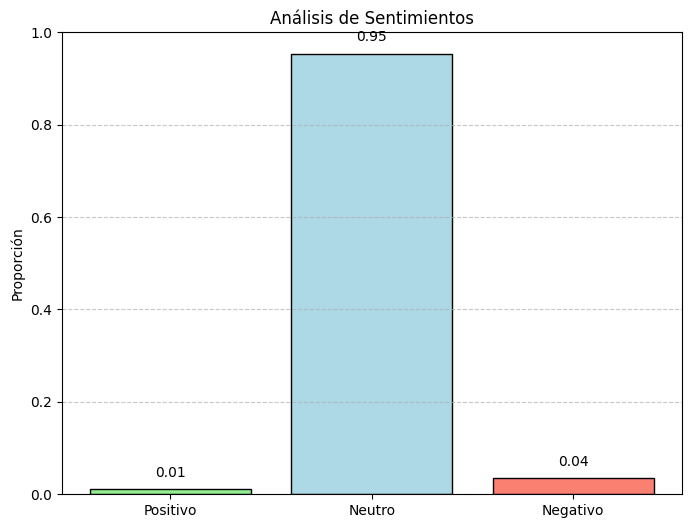


Resumen: El sentimiento general es neutral.


In [16]:
from nltk.sentiment import SentimentIntensityAnalyzer
import nltk
import matplotlib.pyplot as plt

nltk.download('vader_lexicon')


sia = SentimentIntensityAnalyzer()


sentimiento = sia.polarity_scores(texto)


print("\nAnálisis de sentimientos:")
print(f"Positivo: {sentimiento['pos']}")
print(f"Neutro: {sentimiento['neu']}")
print(f"Negativo: {sentimiento['neg']}")
print(f"Combinado (compound): {sentimiento['compound']}")

# Visualización de los resultados en un gráfico de barras
labels = ['Positivo', 'Neutro', 'Negativo']
scores = [sentimiento['pos'], sentimiento['neu'], sentimiento['neg']]
colors = ['lightgreen', 'lightblue', 'salmon']

plt.figure(figsize=(8, 6))
plt.bar(labels, scores, color=colors, edgecolor='black')
plt.title('Análisis de Sentimientos')
plt.ylabel('Proporción')
plt.ylim(0, 1)
plt.grid(axis='y', linestyle='--', alpha=0.7)


for i, score in enumerate(scores):
    plt.text(i, score + 0.02, f"{score:.2f}", ha='center', va='bottom')

plt.show()


if sentimiento['compound'] >= 0.1:
    resumen = "El sentimiento general es positivo."
elif sentimiento['compound'] >= 0.1:
    resumen = "El sentimiento general es negativo."
else:
    resumen = "El sentimiento general es neutral."

print(f"\nResumen: {resumen}")



## Extraccion de Entidades
- **PERSON**:
  - Cantidad: **5,000+**

- **ORGANIZATION**:
  - Cantidad: Aproximadamente **2,000**
  - Observación: Las organizaciones también tienen una presencia considerable, lo que indica que el análisis puede incluir comentarios o referencias a instituciones, empresas o grupos relevantes.

- **GPE (Geopolitical Entity)**:
  - Cantidad: Menos de **1,000**

- **GSP (Geo-Political Subdivision)**:
  - Cantidad: Muy baja

- **FACILITY**:
  - Cantidad: Mínima


[nltk_data] Downloading package maxent_ne_chunker to
[nltk_data]     C:\Users\MG\AppData\Roaming\nltk_data...
[nltk_data]   Package maxent_ne_chunker is already up-to-date!
[nltk_data] Downloading package words to
[nltk_data]     C:\Users\MG\AppData\Roaming\nltk_data...
[nltk_data]   Package words is already up-to-date!
[nltk_data] Downloading package averaged_perceptron_tagger to
[nltk_data]     C:\Users\MG\AppData\Roaming\nltk_data...
[nltk_data]   Package averaged_perceptron_tagger is already up-to-
[nltk_data]       date!
[nltk_data] Downloading package averaged_perceptron_tagger_eng to
[nltk_data]     C:\Users\MG\AppData\Roaming\nltk_data...
[nltk_data]   Package averaged_perceptron_tagger_eng is already up-to-
[nltk_data]       date!
[nltk_data] Downloading package maxent_ne_chunker_tab to
[nltk_data]     C:\Users\MG\AppData\Roaming\nltk_data...
[nltk_data]   Unzipping chunkers\maxent_ne_chunker_tab.zip.
[nltk_data] Downloading package punkt to
[nltk_data]     C:\Users\MG\AppData


Entidades nombradas extraídas:
Abril (PERSON)
Vargas Pérez (PERSON)
PT Valorada (ORGANIZATION)
Escandalizada (PERSON)
Estoy (PERSON)
Meta (ORGANIZATION)
Para (PERSON)
Coursera Plus (PERSON)
Duré (PERSON)
Quizás (PERSON)
Valorada (PERSON)
Fecha (PERSON)
Valorada (PERSON)
Fecha (PERSON)
Valorada (PERSON)
ESTAFADORES (ORGANIZATION)
Fecha (PERSON)
ES Valorada (ORGANIZATION)
ESTAFADORES (ORGANIZATION)
ESTAFADORES (ORGANIZATION)
Mismo (PERSON)
Fecha (PERSON)
Maria Eugenia Simancas Soriano (PERSON)
US Valorada (ORGANIZATION)
Cuidado (PERSON)
Son (PERSON)
Además (PERSON)
Fecha (PERSON)
US Valorada (ORGANIZATION)
Creo (PERSON)
Courser Learner (PERSON)
Curso (PERSON)
Universidad (GPE)
Fecha (PERSON)
Valorada (PERSON)
Leí (PERSON)
Coursera (GPE)
Fecha (PERSON)
Jeanpierre Nuñez (PERSON)
Valorada (PERSON)
Microsoft (ORGANIZATION)
Ya (PERSON)
Porqueria (GPE)
Fecha (PERSON)
Cristian (GPE)
Valorada (PERSON)
Realmente (PERSON)
Pésimo (PERSON)
Fecha (PERSON)
Determina (GPE)
Maha Visnu Da Silva (PERSON)

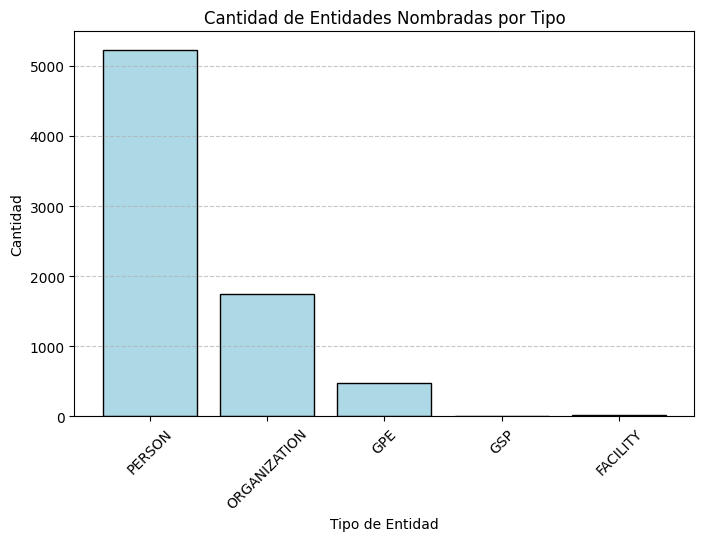

In [22]:
import nltk
from nltk.tokenize import word_tokenize
import matplotlib.pyplot as plt

# Descargar los recursos necesarios
nltk.download('maxent_ne_chunker')
nltk.download('words')
nltk.download('averaged_perceptron_tagger')
nltk.download('averaged_perceptron_tagger_eng')
nltk.download('maxent_ne_chunker_tab')
nltk.download('punkt')  # También se necesita para la tokenización

# Lectura del archivo de texto
try:
    with open('datos.txt', 'r', encoding='utf-8') as file:
        texto = file.read()

    # Tokenización del texto en palabras
    tokens = word_tokenize(texto)

    # Etiquetado gramatical (POS tagging)
    tags = nltk.pos_tag(tokens)

    # Identificación de entidades nombradas
    entidades_nombradas = nltk.ne_chunk(tags)

    # Extraer las entidades nombradas
    entidades = []
    for subtree in entidades_nombradas:
        if isinstance(subtree, nltk.Tree):
            entidad = " ".join([token for token, pos in subtree.leaves()])
            tipo_entidad = subtree.label()
            entidades.append((entidad, tipo_entidad))

    print("\nEntidades nombradas extraídas:")
    for entidad, tipo_entidad in entidades:
        print(f"{entidad} ({tipo_entidad})")

    # Contar las entidades por tipo
    tipos_entidades = {}
    for _, tipo in entidades:
        if tipo in tipos_entidades:
            tipos_entidades[tipo] += 1
        else:
            tipos_entidades[tipo] = 1

    # Visualización de las entidades nombradas por tipo
    plt.figure(figsize=(8, 5))
    plt.bar(tipos_entidades.keys(), tipos_entidades.values(), color='lightblue', edgecolor='black')
    plt.title('Cantidad de Entidades Nombradas por Tipo')
    plt.xlabel('Tipo de Entidad')
    plt.ylabel('Cantidad')
    plt.xticks(rotation=45)
    plt.grid(axis='y', linestyle='--', alpha=0.7)
    plt.show()

except FileNotFoundError:
    print("Error: El archivo 'datos.txt' no se encontró. Verifica la ruta y nombre del archivo.")
except Exception as e:
    print(f"Se produjo un error al procesar el archivo de texto: {e}")
